<a href="https://colab.research.google.com/github/theMorana/HSE/blob/main/Homework_2_interface.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Part I

##1.1 Neccesary materials

###Text classification task guide:
* Text classification is a common NLP task that assigns a label or class to text. It helps to load the dataset, prepare the text for classification, apply the evaluation method, configure TrainingArguments and Trainer, as well as connect compute_metrics to calculate metrics during evaluation.
* For text classification, the key ones are num_labels in the model (number of classes), max_length during tokenization (balance between text completeness and cost of calculations), per_device_train_batch_size (affects gradient stability and memory consumption) and eval_strategy (frequency of evaluation). compute_metrics is critical because without it, Trainer returns only eval_loss, and accuracy/F1 must be calculated manually.

Code example:
```python
import numpy as np
import evaluate
accuracy = evaluate.load("accuracy")

def compute_metrics(eval_pred):
    predictions, labels = eval_pred
    predictions = np.argmax(predictions, axis=1)
    return accuracy.compute(predictions=predictions, references=labels)

```

###Trainer Documentation
* The Trainer class provides an API for feature-complete training in PyTorch, and it supports distributed training on multiple GPUs/TPUs, mixed precision for NVIDIA GPUs, AMD GPUs, and torch.amp for PyTorch. Trainer goes hand-in-hand with the TrainingArguments class, which offers a wide range of options to customize how a model is trained. Together, these two classes provide a complete training API.
* Important for text classification are: learning_rate, num_train_epochs (2-4), warmup_ratio or warmup_steps (stabilizes the start of learning), load_best_model_at_end=True in combination with metric_for_best_model (allows you to save the best checkpoint for F1, not loss), and EarlyStoppingCallback to stop in the absence of improvements. compute_metrics accepts an EvalPrediction object (the predictions and label_ids fields) and returns a dictionary of metrics.

Code example:
```python
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_imdb["train"],
    eval_dataset=tokenized_imdb["test"],
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

trainer.train()
```

###Datasets
* Load is specified to download data from Hugging Face Hub, local files, and in-memory data.
* Crucial aspects - split, renamilng labels.

Code example:
```python
from datasets import load_dataset
dataset = load_dataset("lhoestq/demo1")
```

###Evaluate:
* Allows you to calculate metrics that evaluate the classification quality of the model (f1).
* For unbalanced text datasets, `average="macro"` is preferable: it shows how well the model works for each class, not just the dominant one.


Code example:
```python
@evaluate.utils.file_utils.add_start_docstrings(_DESCRIPTION, _KWARGS_DESCRIPTION)
class F1(evaluate.Metric):
    def _info(self):
        return evaluate.MetricInfo(
            description=_DESCRIPTION,
            citation=_CITATION,
            inputs_description=_KWARGS_DESCRIPTION,
            features=datasets.Features(
                {
                    "predictions": datasets.Sequence(datasets.Value("int32")),
                    "references": datasets.Sequence(datasets.Value("int32")),
                }
                if self.config_name == "multilabel"
                else {
                    "predictions": datasets.Value("int32"),
                    "references": datasets.Value("int32"),
                }
            ),
            reference_urls=["https://scikit-learn.org/stable/modules/generated/sklearn.metrics.f1_score.html"],
        )

    def _compute(self, predictions, references, labels=None, pos_label=1, average="binary", sample_weight=None):
        score = f1_score(
            references, predictions, labels=labels, pos_label=pos_label, average=average, sample_weight=sample_weight
        )
        return {"f1": score if getattr(score, "size", 1) > 1 else float(score)}

```


##Question 1
With `single_label_classification`, each example belongs to exactly one class. Labels are whole indexes (0, 1, 2, ...). The model applies `CrossEntropyLoss` to form logs (batch, num_labels) and form indexes (batch,). The probabilities of the classes compete with each other: the sum of the softmax across the classes is 1.

With `multi_label_classification`, an example can belong to several classes at the same time. Labels are a binary vector of the form (batch, num_labels) with values 0.0/1.0. The model applies BCEWithLogitsLoss to each logit independently. Each class is solved separately: the sigmoid gives independent probabilities, the sum of which does not have to be equal to 1.

Choosing the wrong `problem_type` will either lead to a dimension error (CrossEntropy expects indexes, gets a float vector), or to logically incorrect learning (BCE on mutually exclusive classes).

##Question 2
The tokenizer argument has been renamed to `processing_class` because the Trainer must accept not only tokenizers, but also an ImageProcessor or FeatureExtractor. (from here - https://github.com/huggingface/transformers/pull/32385#top)

##Question 3
The `Trainer` source code has a condition: if `self.compute_metrics` is not None, `compute_metrics(EvalPrediction(...))` is called; otherwise, the metrics block is skipped. With `compute_metrics=None`, `prediction_loss_only=True` is set — the Trainer collects only the loss, without saving predictions and labels.

#Part II

Theme - Sentiment Analysis Theme (imdb dataset)
Model - distilbert-base-uncased




In [1]:
!pip install transformers datasets evaluate scikit-learn torch

In [2]:
import random
import time
from dataclasses import dataclass, field
from collections import Counter
import evaluate
from sklearn.metrics import confusion_matrix

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments,
    DataCollatorWithPadding,
    EarlyStoppingCallback
)
from datasets import load_dataset


In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"device = {device}")
print(f"torch = {torch.__version__}")

device = cuda
torch = 2.14.1+cu130


In [20]:
dataset = load_dataset("stanfordnlp/imdb")
train_raw = dataset["train"].shuffle(seed=42).select(range(4000))
eval_raw = dataset["test"].shuffle(seed=42).select(range(1000))
class_names = ["neg", "pos"]

```python
Config            — all hyperparameters and paths
DataModule        — download, split, tokenization of dataset
ModelFactory      — creating a model and tokenizer
MetricsCalculator — accuracy, f1_macro, confusion matrix
TrainerWrapper    — wrapper over transformers. Trainer + early stopping
Experiment        — orchestrator
```

In [21]:
@dataclass
class ExperimentConfig:
    name: str
    model_name: str = "distilbert-base-uncased"
    learning_rate: float = 2e-5
    num_epochs: int = 3
    batch_size: int = 16
    eval_batch_size: int = 32
    max_length: int = 128
    metric_for_best_model: str = "f1_macro"
    early_stopping_patience: int = 2
    output_dir: str = "./results"
    num_labels: int = 2
    device: torch.device = None
    seed: int = 42

    def __post_init__(self):
        self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [22]:
class DataModule:
    def __init__(self, config, train_raw, eval_raw):
        self.config = config
        self.train_raw = train_raw
        self.eval_raw = eval_raw
        self.tokenizer = None
        self.train_ds = None
        self.eval_ds = None

    def tokenize(self):
        self.tokenizer = AutoTokenizer.from_pretrained(self.config.model_name)

        def tokenize_fn(example):
            return self.tokenizer(
                example["text"],
                truncation=True,
                max_length=self.config.max_length,
            )

        self.train_ds = self.train_raw.map(tokenize_fn, batched=True)
        self.eval_ds = self.eval_raw.map(tokenize_fn, batched=True)

    def prepare(self):
        self.tokenize()
        cols = ["input_ids", "attention_mask", "label"]
        self.train_ds.set_format("torch", columns=cols)
        self.eval_ds.set_format("torch", columns=cols)
        return self

    def get_splits(self):
        return self.train_ds, self.eval_ds

In [23]:
class ModelFactory:
  def __init__(self, config):
        self.config = config

  def build(self):
        model = AutoModelForSequenceClassification.from_pretrained(
            self.config.model_name,
            num_labels=self.config.num_labels,
        )
        return model.to(self.config.device)

In [24]:
class MetricsCalculator:
    def __init__(self, config):
        self.config = config
        self.accuracy = evaluate.load("accuracy")
        self.f1 = evaluate.load("f1")

    def compute(self, eval_pred):
        logits, labels = eval_pred
        preds = np.argmax(logits, axis=-1)
        acc = self.accuracy.compute(predictions=preds, references=labels)["accuracy"]
        f1 = self.f1.compute(
            predictions=preds, references=labels, average="macro"
        )["f1"]
        return {"accuracy": acc, "f1_macro": f1}

    def confusion(self, y_true, y_pred):
        cm = confusion_matrix(y_true, y_pred)
        print("Confusion matrix:")
        print(cm)
        return cm

    def report(self, results):
        keys = ["eval_accuracy", "eval_f1_macro", "eval_loss"]
        print(f"{'metric':<20}{'value':>10}")
        print("-" * 30)
        for k in keys:
            v = results.get(k)
            print(f"{k:<20}{v:>10.4f}" if isinstance(v, float) else f"{k:<20}{v:>10}")

In [25]:
class TrainerWrapper:
    def __init__(self, config, model, tokenizer, metrics):
        self.config = config
        self.model = model
        self.tokenizer = tokenizer
        self.metrics = metrics
        self.trainer = None

    def build(self, train_ds, eval_ds):
        training_args = TrainingArguments(
            output_dir=f"{self.config.output_dir}/{self.config.name}",
            learning_rate=self.config.learning_rate,
            num_train_epochs=self.config.num_epochs,
            per_device_train_batch_size=self.config.batch_size,
            per_device_eval_batch_size=self.config.eval_batch_size,
            eval_strategy="epoch",
            save_strategy="epoch",
            load_best_model_at_end=True,
            metric_for_best_model=self.config.metric_for_best_model,
            greater_is_better=True,
            logging_steps=50,
            report_to="none",
            seed=self.config.seed,
        )

        self.trainer = Trainer(
            model=self.model,
            args=training_args,
            train_dataset=train_ds,
            eval_dataset=eval_ds,
            data_collator=DataCollatorWithPadding(tokenizer=self.tokenizer),
            compute_metrics=self.metrics.compute,
            callbacks=[
                EarlyStoppingCallback(
                    early_stopping_patience=self.config.early_stopping_patience
                )
            ],
        )
        return self

    def train(self):
        self.trainer.train()
        return self

    def evaluate(self):
        return self.trainer.evaluate()

    def predict(self, dataset):
        preds = self.trainer.predict(dataset)
        y_pred = np.argmax(preds.predictions, axis=-1)
        y_true = preds.label_ids
        return y_true, y_pred

    def save(self):
        path = f"{self.config.output_dir}/{self.config.name}"
        self.trainer.save_model(path)
        return path

In [26]:
class Experiment:
    def __init__(self, config, train_raw, eval_raw):
        self.config = config
        self.train_raw = train_raw
        self.eval_raw = eval_raw
        self.results = None
        self.cm = None
        self.y_true = None
        self.y_pred = None
        self.trainer = None
        self.model = None
        self.data = None

    def run(self):
        self.data = DataModule(
            self.config,
            self.train_raw,
            self.eval_raw
        ).prepare()

        train_ds, eval_ds = self.data.get_splits()

        # model
        self.model = ModelFactory(self.config).build()
        metrics = MetricsCalculator(self.config)

        self.trainer = TrainerWrapper(
            self.config,
            self.model,
            self.data.tokenizer,
            metrics
        ).build(train_ds, eval_ds)
        self.trainer.train()

        # metrics
        self.results = self.trainer.evaluate()

        # predictions
        self.y_true, self.y_pred = self.trainer.predict(eval_ds)
        self.cm = metrics.confusion(
            self.y_true,
            self.y_pred
        )

        # model save
        self.model_path = self.trainer.save()

        return self.results, self.cm

    def print_report(self):
        if self.results is None:
            print("Сначала необходимо запустить эксперимент.")
            return

        MetricsCalculator(self.config).report(self.results)

In [27]:
config = ExperimentConfig(name="imdb-distilbert")
experiment = Experiment(config, train_raw, eval_raw)
results, cm = experiment.run()
experiment.print_report()

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,0.411444,0.411357,0.817000,0.815189
2,0.226965,0.445085,0.828000,0.827824
3,0.164736,0.489896,0.833000,0.832998


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,F1 Macro
0.164736,0.489896,3,0.833000,0.832998


Confusion matrix:
[[418  94]
 [ 73 415]]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

metric                   value
------------------------------
eval_accuracy           0.8330
eval_f1_macro           0.8330
eval_loss               0.4899


=== Final ===


,value
eval_loss,0.489896
eval_accuracy,0.833000
eval_f1_macro,0.832998


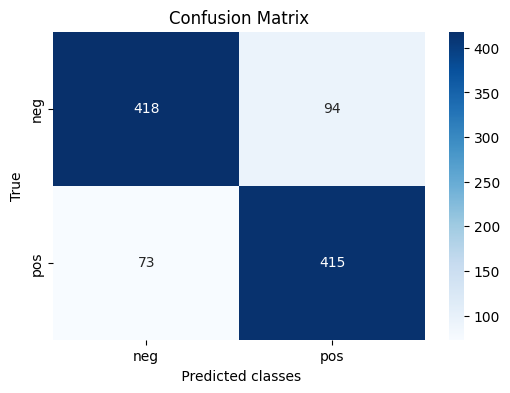

In [28]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# results
df_results = pd.DataFrame([results])
columns_to_show = ["eval_loss", "eval_accuracy", "eval_f1_macro"]
df_display = df_results[columns_to_show].T
df_display.columns = ["value"]
print("=== Final ===")
display(df_display)

# 2. Confusion Matrix (визуализация)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel(" Predicted classes")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()

In [38]:
y_true = experiment.y_true
y_pred = experiment.y_pred
texts = list(eval_raw["text"])

class_names = ["neg", "pos"]

df = pd.DataFrame({
    "text": texts,
    "true": y_true,
    "pred": y_pred
})

df["true_name"] = df["true"].map({0: "neg", 1: "pos"})
df["pred_name"] = df["pred"].map({0: "neg", 1: "pos"})
errors = df[df["true"] != df["pred"]]

print("--- Mistakes ---")
print(f"Total: {len(errors)} from {len(y_true)}\n")

print(errors.groupby(["true_name", "pred_name"]).size())

print("\n---Examples ---")

for (true_cls, pred_cls), group in errors.groupby(
    ["true_name", "pred_name"]
):
    print(
        f"\nPair: True '{true_cls}' -> "
        f"Prediction '{pred_cls}' "
        f"(total {len(group)})"
    )
    print("-" * 80)

    for idx, row in group.head(3).iterrows():
        text = row["text"].replace("\n", " ")[:300]
        print(f"[index {idx}] {text}...\n")


--- Mistakes ---
Total: 167 from 1000

true_name  pred_name
neg        pos          94
pos        neg          73
dtype: int64

---Examples ---

Pair: True 'neg' -> Prediction 'pos' (total 94)
--------------------------------------------------------------------------------
[index 16] The story is: a turn-of-the-century troupe of actors, along with producers and theatre-owners, have very complicated relationships. A resident playwright has written a psychological drama. He wants to get a good production on stage, but can't unless he convinces a pariticular reviewer to revisit the...

[index 21] Coming from Kiarostami, this art-house visual and sound exposition is a surprise. For a director known for his narratives and keen observation of humans, especially children, this excursion into minimalist cinematography begs for questions: Why did he do it? Was it to keep him busy during a vacation...

[index 39] This is about some vampires (who can run around out in the sunlight), that are caus

#Part III

In [39]:
import random

# 5 random mistakes
num_samples = min(5, len(errors))
random_indices = random.sample(list(errors.index), num_samples)
print(f"Examples of false predictions: ({num_samples}):\n")

for i, idx in enumerate(random_indices, 1):
    print(f"--- Example {i} ---")
    print(f"Text: {texts[idx]}")
    print(f"True: {'pos' if y_true[idx] == 1 else 'neg'}")
    print(f"Prediction: {'pos' if y_pred[idx] == 1 else 'neg'}")
    print()


Examples of false predictions: (5):

--- Example 1 ---
Text: It is an interesting fact that metaphysics by Platon and Aristoteles, formal logic and abstract ontology form about those sciences that most people are not interested in. But then, around one thousand years after Aristoteles, the computer began to usurp the human thinking, and the humans who were refusing to reflect questions of being other than biological, physical and chemical ones, suddenly felt paralyzed because they could not cope with the consequences that this computers would bring "over night". R.W. Fassbinder's "Welt Am Draht", together with Tarkovsky's "Solaris" and Godard's "Alphaville", is probably the first movie who took the philosophical questions of emerging computer science as a basis of a story to be told in a movie. The confusing questions about identities and realities are cleverly built into different interwoven criminal stories which the audience really tries to follow because it is interested to solve t

| Text| True | Prediction | Explanation |
|--| -- | -- | -- |
| I'm a Boorman fan, but this is arguably his least successful film...             | neg  | pos        | Mixed sentiment: positive comments about the actress outweigh the overall negative evaluation.              |
| I have seen both the MST3K version and the uncut version. I rather enjoyed it... | neg  | pos        | Ambiguous labeling: predominantly positive sentiment despite the negative ground-truth label.               |
| This must be one of the most horribly titled films of all time...                | pos  | neg        | Predominance of negative evaluative vocabulary despite the overall positive sentiment.                      |
| Going into the movie with the right expectations, I somewhat liked this movie... | neg  | pos        | Mixed sentiment: negative plot evaluation combined with positive comments about acting, dancing, and music. |
| Some will say this movie is a guilty pleasure. I loved this flick...             | pos  | neg        | Irony and context-dependent vocabulary: negative words are used in a positive context.                      |



#Part IV

The `Processor` is responsible for preparing the inputs, not the `Tokenizer`, because its task is to combine several modalities into a single format. `Tokenizer` can only work with text. The `Processor` internally contains both a tokenizer for text and a separate image processor (`Image Processor`) that performs resize, normalization, and transformation of the image into the pixel_values tensor. In addition, `Processor` implements the logic of chat templates for multimodal dialogues: it places special placeholders for images in the text and synchronizes them with visual embeddings.